# RQ2 validation: automatic paired diagnostic

Creator TIB `valid` only, pinned revision `e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee`. These 20 S1/S3 summaries use a deterministic mostly extractive engine and lexical structure; this is **not** the formal controlled study. The provided abstracts are noisy proxies. ROUGE-L measures similarity to those abstracts, and source lexical overlap measures shared word types. Neither measures factuality. No blinded or other human scoring is used. The sealed `test` split is not accessed.

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
root=Path.cwd()
receipt=root/'experiments/outputs/diagnostic/rq2_valid_paired/automatic_evaluation.json'
d=json.loads(receipt.read_text(encoding='utf-8'))
assert d['split']=='valid' and d['test_content_accessed'] is False and d['n']==20
print('Receipt:',receipt)
print('Status:',d['status'],'| n=',d['n'])
print('Dataset revision:',d['revision'])

Receipt: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\diagnostic\rq2_valid_paired\automatic_evaluation.json
Status: validation_automatic_diagnostic_only | n= 20
Dataset revision: e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee


In [2]:
rows=[]
for r in d['rows']:
    rows.append({'DOI':r['doi'].split()[0], 'abstract_words':r['abstract_words'], 'reference_screen':r['reference_screen'], 'source_truncated':r['source_prefix_truncated'], 'S1_ROUGE_L':r['arms']['S1']['rouge_l_abstract_proxy'], 'S3_ROUGE_L':r['arms']['S3']['rouge_l_abstract_proxy'], 'd_ROUGE_L':r['delta_s3_minus_s1']['rouge_l_abstract_proxy'], 'S1_source_overlap':r['arms']['S1']['source_lexical_support_proxy'], 'S3_source_overlap':r['arms']['S3']['source_lexical_support_proxy'], 'd_source_overlap':r['delta_s3_minus_s1']['source_lexical_support_proxy'], 'S1_prompt_est':r['arms']['S1']['cumulative_prompt_token_estimate'], 'S3_prompt_est':r['arms']['S3']['cumulative_prompt_token_estimate']})
df=pd.DataFrame(rows)
display(df.round(4))
print('Truncated source:',int(df.source_truncated.sum()),'/20; abstract <30 words:',int((df.abstract_words<30).sum()),'/20')

,DOI,abstract_words,reference_screen,source_truncated,S1_ROUGE_L,S3_ROUGE_L,d_ROUGE_L,S1_source_overlap,S3_source_overlap,d_source_overlap,S1_prompt_est,S3_prompt_est
0,10.5446/20846,81,candidate_unverified,True,0.1117,0.1105,-0.0012,0.9429,0.9091,-0.0338,9409,8547
1,10.5446/43747,11,unsuitable,True,0.0367,0.0374,0.0007,0.9437,0.9079,-0.0358,9473,8650
2,10.5446/15101,23,candidate_unverified,True,0.0833,0.0833,0.0000,0.9091,0.8657,-0.0434,9191,8440
3,10.5446/38638,3,unsuitable,False,0.0000,0.0000,0.0000,0.9344,0.8333,-0.1011,6189,5703
4,10.5446/49452,14,candidate_unverified,False,0.1468,0.1468,0.0000,0.9016,0.8529,-0.0487,3935,3703
5,10.5446/35254,13,candidate_unverified,True,0.0536,0.0536,0.0000,0.9434,0.9074,-0.0360,10062,8993
6,10.5446/49509,19,candidate_unverified,False,0.1043,0.0909,-0.0134,0.9062,0.8730,-0.0332,3612,3289
7,10.5446/50943,95,unsuitable,True,0.1015,0.1809,0.0794,0.9254,0.8769,-0.0485,9379,8531
8,10.5446/38319,89,unsuitable,True,0.1368,0.1368,0.0000,0.9583,0.9048,-0.0536,13906,11185
9,10.5446/14078,68,unsuitable,True,0.1098,0.0976,-0.0122,0.9552,0.9032,-0.0520,9270,8556


Truncated source: 13 /20; abstract <30 words: 9 /20


In [3]:
paired=pd.DataFrame([{'metric':k,'n':v['n'],'mean_S3_minus_S1':v['mean_s3_minus_s1'],'CI_low':v['ci95'][0],'CI_high':v['ci95'][1]} for k,v in d['paired'].items()])
display(paired.round(4))
strata=pd.DataFrame([{'subset':k,'n':v['n'],'ROUGE_delta':v['paired']['rouge_l_abstract_proxy']['mean_s3_minus_s1'],'ROUGE_CI':str([round(z,4) for z in v['paired']['rouge_l_abstract_proxy']['ci95']])} for k,v in d['strata'].items()])
display(strata)
print('Limits:', json.dumps(d['limits'],ensure_ascii=False))

,metric,n,mean_S3_minus_S1,CI_low,CI_high
0,rouge_l_abstract_proxy,20,0.0056,-0.0066,0.0195
1,source_lexical_support_proxy,20,-0.0445,-0.0538,-0.0362


,subset,n,ROUGE_delta,ROUGE_CI
0,full_transcript,7,-0.006136,"[-0.017, 0.0045]"
1,prefix_truncated,13,0.011878,"[-0.0055, 0.0319]"
2,abstract_under_30_words,9,-0.002915,"[-0.0116, 0.0041]"
3,abstract_at_least_30_words,11,0.012518,"[-0.008, 0.0368]"
4,reference_candidate_unverified,12,0.008622,"[-0.0059, 0.0264]"
5,reference_unsuitable,8,0.001000,"[-0.0165, 0.0265]"
6,both_arms_within_estimated_prompt_cap,7,-0.006136,"[-0.017, 0.0045]"


Limits: {"generator": "deterministic mostly extractive heuristic", "source_prefix_truncated_n": 13, "either_arm_prompt_cap_exceeded_n": 13, "abstract_short_under_30_words_n": 9, "actual_equal_token_budget_verified": false, "factuality_measured": false, "reference_validity_verified": false}


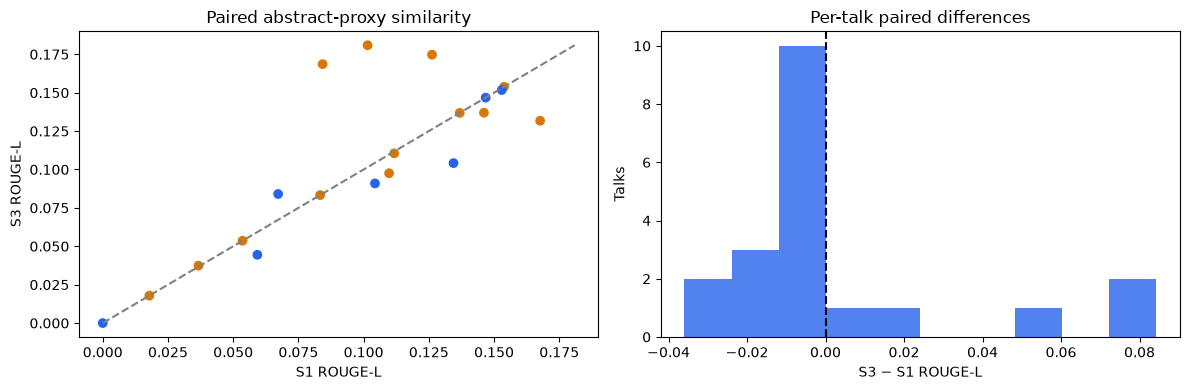

In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].scatter(df.S1_ROUGE_L,df.S3_ROUGE_L,c=df.source_truncated.map({True:'#d97706',False:'#2563eb'}))
lo=min(df.S1_ROUGE_L.min(),df.S3_ROUGE_L.min()); hi=max(df.S1_ROUGE_L.max(),df.S3_ROUGE_L.max())
ax[0].plot([lo,hi],[lo,hi],color='gray',linestyle='--'); ax[0].set(xlabel='S1 ROUGE-L',ylabel='S3 ROUGE-L',title='Paired abstract-proxy similarity')
ax[1].hist(df.d_ROUGE_L,bins=10,color='#2563eb',alpha=.8); ax[1].axvline(0,color='black',linestyle='--'); ax[1].set(xlabel='S3 − S1 ROUGE-L',ylabel='Talks',title='Per-talk paired differences')
fig.tight_layout(); display(fig); plt.close(fig)

## Interpretation

The observed difference is descriptive and has a wide paired interval around zero. Since 13/20 inputs are prefix truncated, 13/20 pairs exceed the approximate cumulative prompt cap, 9/20 abstracts are under 30 words, and generation is deterministic/extractive, this result cannot answer whether a controlled LLM S3 system improves summary quality. The next run must use the same source span, a declared real generator, measured tokenizer usage and a frozen automatic primary outcome. The 12 `candidate_unverified` and 8 `unsuitable` abstract strata are shown above; candidate status does not verify source support. Visual S4 remains `not_run`: the cohort has keyframe timings but no aligned image pixels/OCR.